# 01 - Data Exploration: Credit Card Default

**Dataset:** UCI *Default of Credit Card Clients* (Taiwan, 2005)  
**File:** `default of credit card clients.xls` (one row = one customer)  
**Target:** `default payment next month` (1 = customer defaulted, 0 = did not)

**Goal of this notebook:** only *look* at the data. No cleaning yet (that is notebook 02).

**Workflow:**
1. Load the data (the header is on the 2nd row)
2. Shape and data types
3. Missing values and duplicates
4. Summary statistics
5. Default rate
6. Undocumented category codes (`EDUCATION`, `MARRIAGE`)
7. Payment status codes (`PAY_0` to `PAY_6`)
8. Negative and odd bill amounts

## Step 1: Load the Data

The Excel file has **two header rows**. Row 1 holds generic names (`X1, X2, ... Y`) and row 2 holds the real names (`LIMIT_BAL, SEX, ...`). `header=1` tells pandas to use the second row (counting starts at 0).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# header=1 -> use the 2nd row of the sheet as column names
df = pd.read_excel("../data/default of credit card clients.xls", header=1)

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Step 2: Shape and Data Types

In [2]:
df.shape   # (rows, columns)

(30000, 25)

In [3]:
df.info()   # data type + non-null count of every column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [4]:
df.columns.tolist()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default payment next month']

**What we see:** 30,000 customers and 25 columns, and **all of them are integers**.

Column meaning (from the UCI description):
- `LIMIT_BAL`: credit limit (NT dollars)
- `SEX`: 1 = male, 2 = female
- `EDUCATION`: 1 = graduate school, 2 = university, 3 = high school, 4 = others
- `MARRIAGE`: 1 = married, 2 = single, 3 = others
- `PAY_0, PAY_2 ... PAY_6`: repayment status from September back to April. There is **no `PAY_1`**, so the numbering skips. We rename it in cleaning.
- `BILL_AMT1-6`: bill statement amount for each month
- `PAY_AMT1-6`: amount paid in each month

## Step 3: Missing Values and Duplicates

In [5]:
# missing values per column (sum of all columns)
print("Total missing values:", df.isna().sum().sum())

Total missing values: 0


In [6]:
# fully duplicated rows (ID makes every row unique, so also check without ID)
print("Duplicated rows (with ID):", df.duplicated().sum())
print("Duplicated rows (without ID):", df.drop(columns=["ID"]).duplicated().sum())

Duplicated rows (with ID): 0
Duplicated rows (without ID): 35


**What we see:** no missing values. No duplicates with `ID`, but **35 rows are exact copies of another customer when we ignore `ID`**. We note this for the cleaning step.

## Step 4: Summary Statistics

In [7]:
# .T flips the table so each column becomes a row (easier to read with 25 columns)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


**What to notice:**
- `BILL_AMT` columns have a **negative minimum**, so some bills are below zero.
- `EDUCATION` goes from 0 to 6 and `MARRIAGE` from 0 to 3, which is more than the documented codes.
- `PAY_` columns start at -2, but the documentation only describes -1 and 1-9.
- `LIMIT_BAL`, `BILL_AMT` and `PAY_AMT` have a max far above the 75% value, a sign of outliers.

## Step 5: Default Rate

In [8]:
# count of each class
df["default payment next month"].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [9]:
# percentage of each class
(df["default payment next month"].value_counts(normalize=True) * 100).round(2)

default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

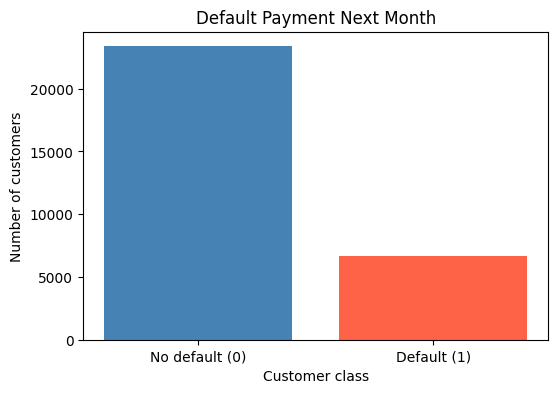

In [10]:
# bar chart of the target
counts = df["default payment next month"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No default (0)", "Default (1)"], counts.values, color=["steelblue", "tomato"])
plt.title("Default Payment Next Month")
plt.xlabel("Customer class")
plt.ylabel("Number of customers")
plt.show()

**What we see:** 6,636 customers (22.12%) defaulted and 23,364 (77.88%) did not. The classes are imbalanced (about 1 to 3.5), so accuracy alone will not be a fair measure in modeling.

## Step 6: Undocumented Category Codes

The documentation says `EDUCATION` should be 1-4 and `MARRIAGE` should be 1-3. Let us check what is really there.

In [11]:
# all EDUCATION codes and how many customers have each
df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [12]:
# customers with an undocumented EDUCATION code (0, 5 or 6)
df.loc[df["EDUCATION"].isin([0, 5, 6]), "EDUCATION"].value_counts().sort_index()

EDUCATION
0     14
5    280
6     51
Name: count, dtype: int64

In [13]:
print("Undocumented EDUCATION rows:", df["EDUCATION"].isin([0, 5, 6]).sum())

Undocumented EDUCATION rows: 345


In [14]:
# all MARRIAGE codes
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

In [15]:
print("Undocumented MARRIAGE rows (code 0):", (df["MARRIAGE"] == 0).sum())

Undocumented MARRIAGE rows (code 0): 54


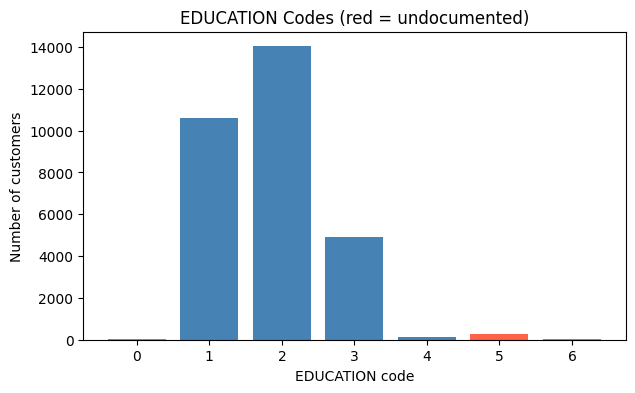

In [16]:
# bar chart of EDUCATION codes (red = not in the documentation)
edu_counts = df["EDUCATION"].value_counts().sort_index()
colors = ["tomato" if code in [0, 5, 6] else "steelblue" for code in edu_counts.index]

plt.figure(figsize=(7, 4))
plt.bar(edu_counts.index.astype(str), edu_counts.values, color=colors)
plt.title("EDUCATION Codes (red = undocumented)")
plt.xlabel("EDUCATION code")
plt.ylabel("Number of customers")
plt.show()

**What we see:**
- `EDUCATION`: code 0 (14), 5 (280) and 6 (51) are not documented, **345 customers** in total.
- `MARRIAGE`: code 0 is not documented, **54 customers**.

These are few rows. In cleaning, the usual fix is to move them into the "others" group (4 for EDUCATION, 3 for MARRIAGE).

## Step 7: Payment Status Codes (`PAY_0` to `PAY_6`)

Documented meaning: -1 = paid on time, 1 = 1 month late, 2 = 2 months late ... 9 = 9+ months late.
-2 and 0 are **not** in the documentation.

In [17]:
# codes found in the most recent month
df["PAY_0"].value_counts().sort_index()

PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

In [18]:
# how many customers have -2 or 0 in PAY_0
print("PAY_0 = -2:", (df["PAY_0"] == -2).sum())
print("PAY_0 =  0:", (df["PAY_0"] == 0).sum())

PAY_0 = -2: 2759
PAY_0 =  0: 14737


**What we see:** 0 is the most common value (14,737 customers) and -2 appears 2,759 times, yet neither is documented. They are usually read as *no delay* (-2 = no credit used, 0 = paid the minimum). They mean "not late", so they do not count as delays.

## Step 8: Negative and Odd Bill Amounts

A bill amount should normally be 0 or more. A negative bill means the customer **paid more than they owed** (a credit balance).

In [19]:
# list of the 6 bill columns
bill_cols = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]

# count of negative bills and the smallest bill in each column
for col in bill_cols:
    print(col, "| negative:", (df[col] < 0).sum(), "| min:", df[col].min())

BILL_AMT1 | negative: 590 | min: -165580
BILL_AMT2 | negative: 669 | min: -69777
BILL_AMT3 | negative: 655 | min: -157264
BILL_AMT4 | negative: 675 | min: -170000
BILL_AMT5 | negative: 655 | min: -81334
BILL_AMT6 | negative: 688 | min: -339603


In [20]:
# customers with at least one negative bill in any month
print("Customers with any negative bill:", (df[bill_cols] < 0).any(axis=1).sum())

Customers with any negative bill: 1930


In [21]:
# odd case 1: bill is zero in all 6 months (card never used)
print("Customers with all 6 bills = 0:", (df[bill_cols] == 0).all(axis=1).sum())

# odd case 2: latest bill is bigger than the credit limit
print("Customers with BILL_AMT1 > LIMIT_BAL:", (df["BILL_AMT1"] > df["LIMIT_BAL"]).sum())

Customers with all 6 bills = 0: 866
Customers with BILL_AMT1 > LIMIT_BAL: 2115


In [22]:
# look at a few of the most negative bills
df.loc[df["BILL_AMT1"] < 0, ["ID", "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].sort_values("BILL_AMT1").head()

,ID,LIMIT_BAL,BILL_AMT1,PAY_AMT1
12330,12331,300000,-165580,505000
23003,23004,250000,-154973,225066
8835,8836,430000,-15308,8
351,352,200000,-14386,10118
29779,29780,50000,-11545,10000


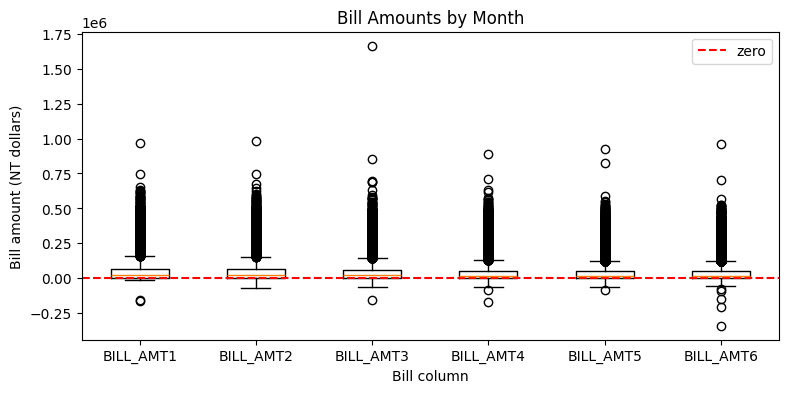

In [23]:
# box plot of the 6 bill columns to see negatives and outliers
plt.figure(figsize=(9, 4))
plt.boxplot([df[col] for col in bill_cols])
plt.xticks(range(1, 7), bill_cols)   # name each box
plt.axhline(0, color="red", linestyle="--", label="zero")
plt.title("Bill Amounts by Month")
plt.xlabel("Bill column")
plt.ylabel("Bill amount (NT dollars)")
plt.legend()
plt.show()

**What we see:**
- Every bill column has between 590 and 688 negative values. The lowest is -339,603 in `BILL_AMT6`.
- **1,930 customers** have at least one negative bill.
- **866 customers** have a zero bill in all 6 months, so they never used the card.
- **2,115 customers** have a latest bill above their credit limit.
- The box plot shows long tails above the boxes, so there are many outliers to treat with IQR in cleaning.

## Summary of Exploration

| Check | Result |
|-------|--------|
| Shape | 30,000 rows x 25 columns, all integers |
| Header | real header on 2nd row (`header=1`) |
| Missing values | 0 |
| Duplicates | 0 with ID, 35 when ID is ignored |
| Default rate | 6,636 of 30,000 = 22.12% |
| Undocumented `EDUCATION` | 0 (14), 5 (280), 6 (51) = 345 rows |
| Undocumented `MARRIAGE` | 0 (54 rows) |
| Undocumented `PAY_` codes | -2 and 0 (e.g. `PAY_0`: 2,759 and 14,737) |
| Negative bills | 1,930 customers with at least one |
| Odd bills | 866 all-zero, 2,115 with bill > limit |
| Naming | `PAY_0` then `PAY_2` (no `PAY_1`) |

**Next notebook (02):** fix these problems.